<a href="https://colab.research.google.com/github/weirdrazak/image_classification_project/blob/main/Image_Classification.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [5]:
from google.colab import drive

drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [20]:
import os
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.image as mpimg

dataset = "/content/drive/MyDrive/competition_dataset"

In [12]:

train_features = pd.read_csv(
    os.path.join(dataset, "train_features.csv"),
    index_col="id"
)

test_features = pd.read_csv(
    os.path.join(dataset, "test_features.csv"),
    index_col="id"
)

train_labels = pd.read_csv(
    os.path.join(dataset, "train_labels.csv"),
    index_col="id"
)

In [9]:
print("Train features:", train_features.shape)
print("Test features:", test_features.shape)
print("Train labels:", train_labels.shape)



Train features: (16488, 2)
Test features: (4464, 2)
Train labels: (16488, 8)


In [10]:
train_features.head()

,filepath,site
id,,
ZJ000000,train_features/ZJ000000.jpg,S0120
ZJ000001,train_features/ZJ000001.jpg,S0069
ZJ000002,train_features/ZJ000002.jpg,S0009
ZJ000003,train_features/ZJ000003.jpg,S0008
ZJ000004,train_features/ZJ000004.jpg,S0036


In [11]:
test_features.head()

,filepath,site
id,,
ZJ016488,test_features/ZJ016488.jpg,S0082
ZJ016489,test_features/ZJ016489.jpg,S0040
ZJ016490,test_features/ZJ016490.jpg,S0040
ZJ016491,test_features/ZJ016491.jpg,S0041
ZJ016492,test_features/ZJ016492.jpg,S0040


In [13]:
train_labels.head()

,antelope_duiker,bird,blank,civet_genet,hog,leopard,monkey_prosimian,rodent
id,,,,,,,,
ZJ000000,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0
ZJ000001,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
ZJ000002,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0
ZJ000003,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
ZJ000004,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0


In [14]:
species_labels = sorted(train_labels.columns.unique())
species_labels

['antelope_duiker',
 'bird',
 'blank',
 'civet_genet',
 'hog',
 'leopard',
 'monkey_prosimian',
 'rodent']

In [22]:
train_img_dir = os.path.join(dataset, "train_features")

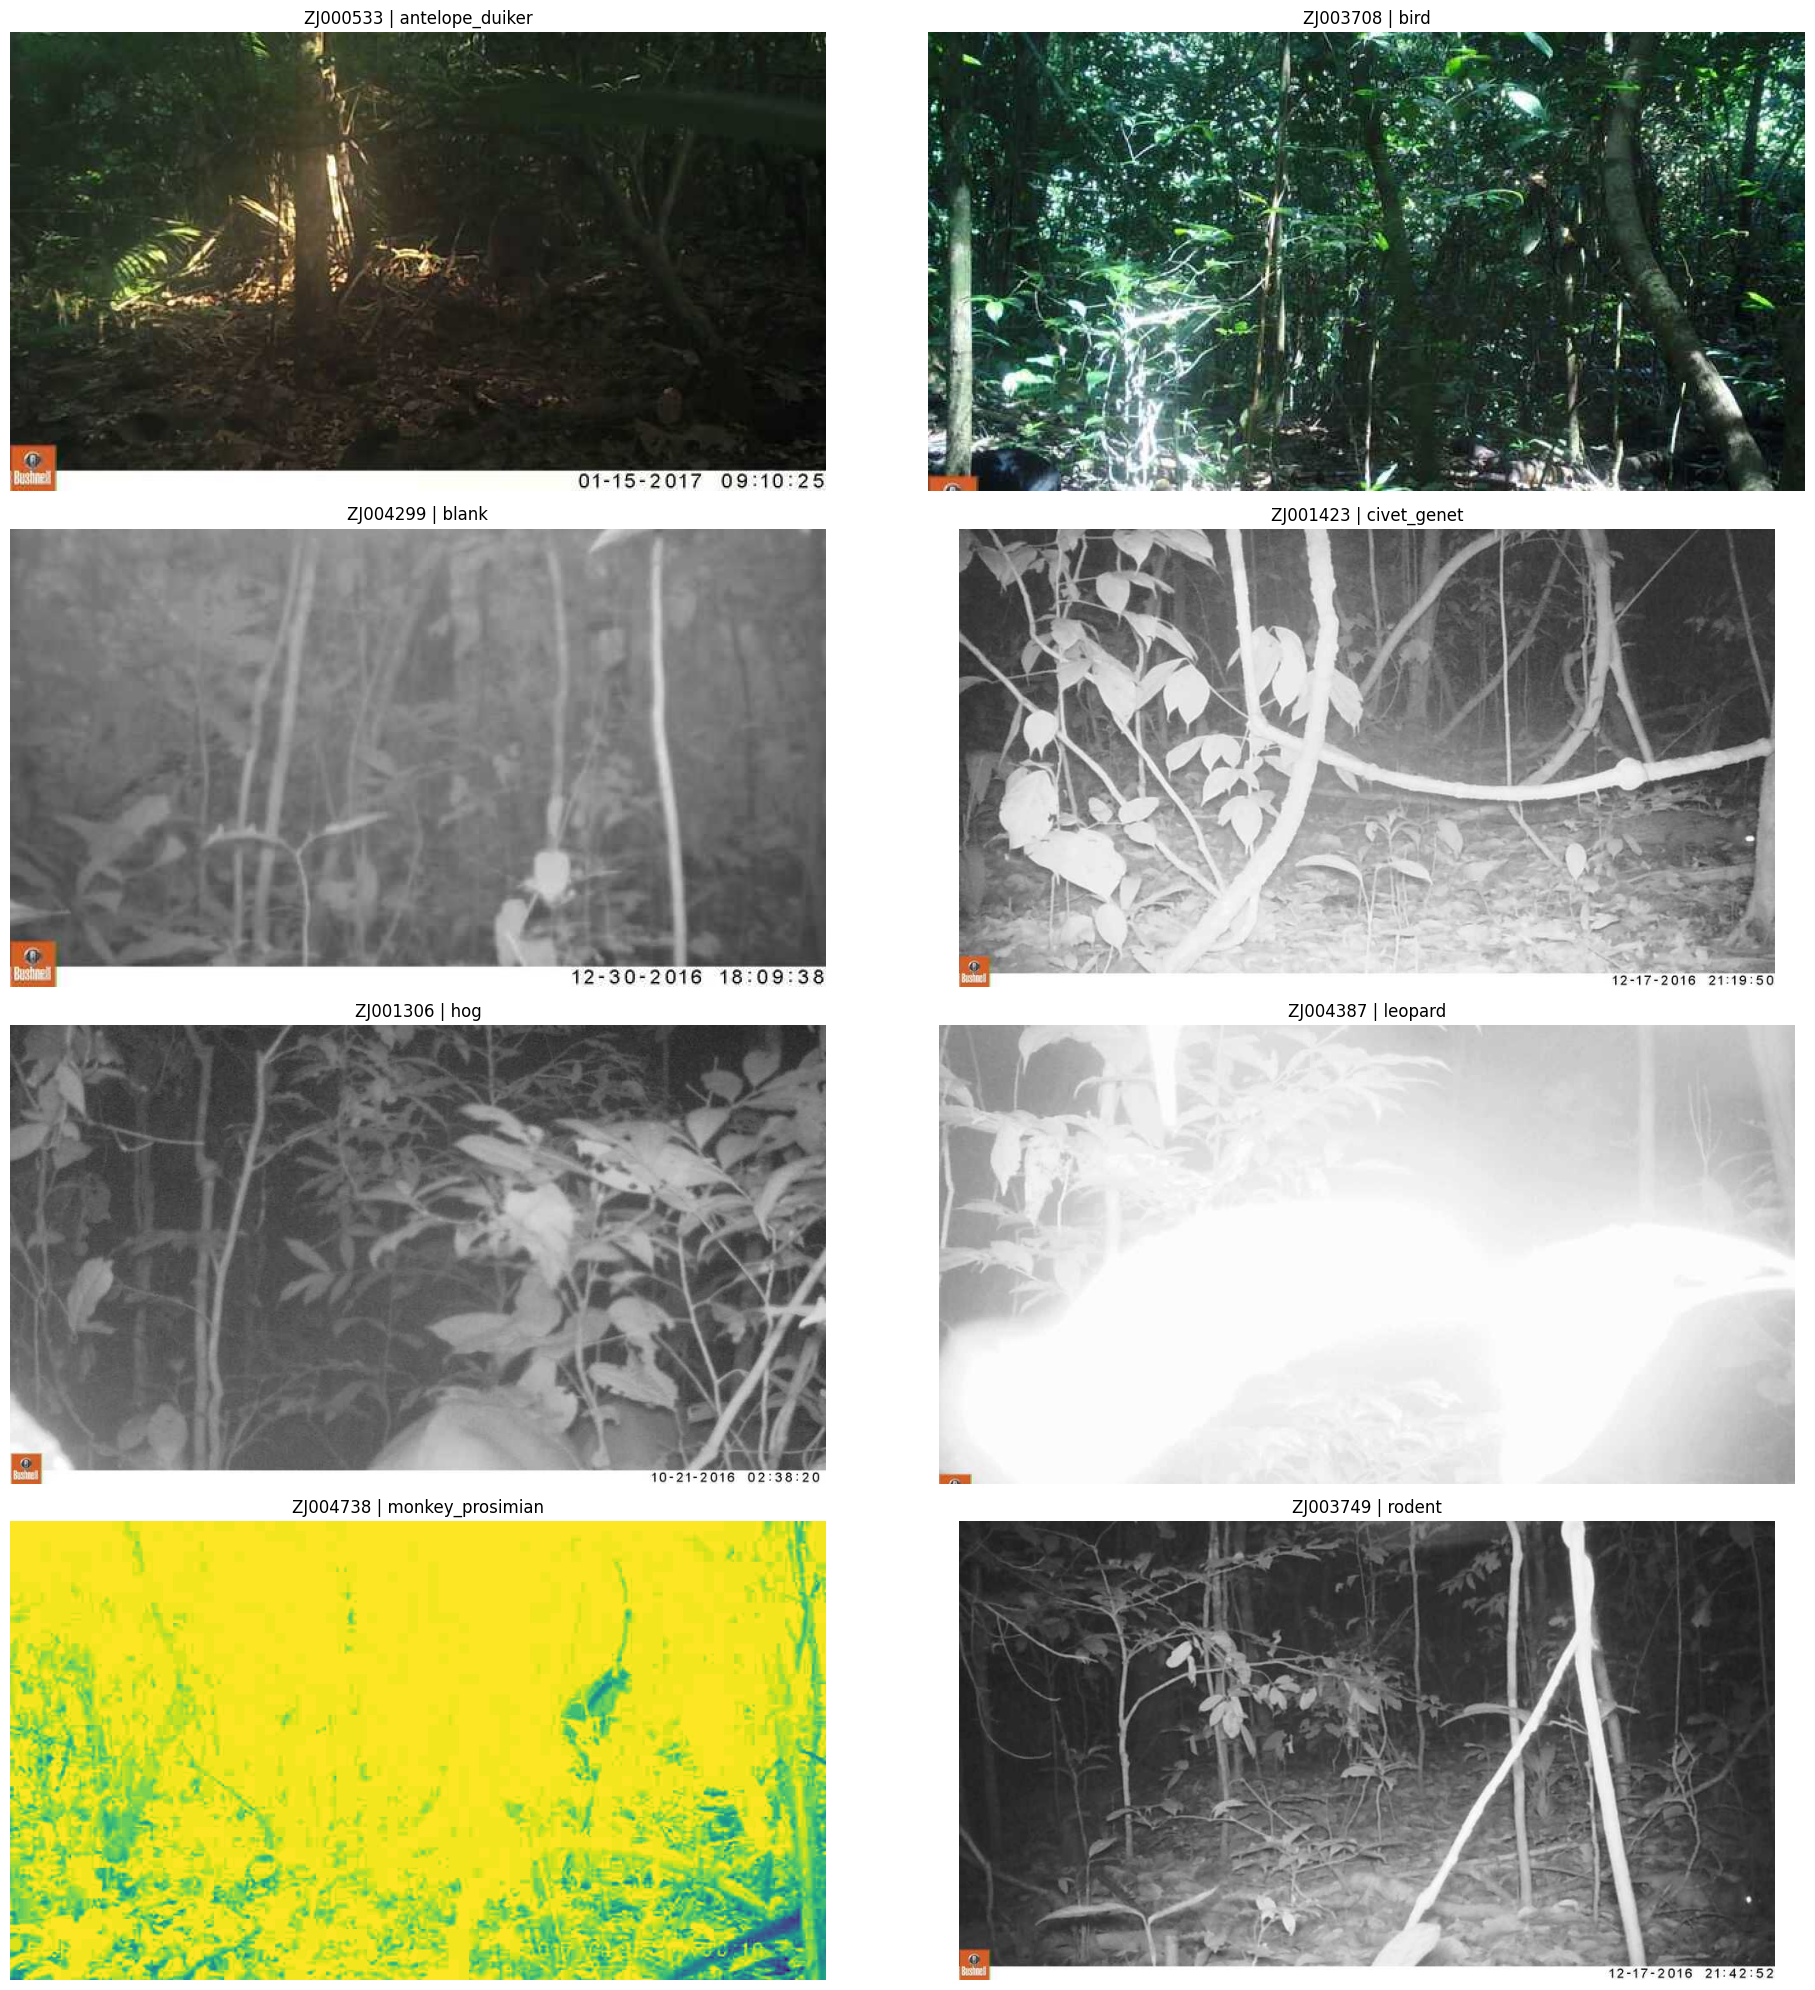

In [23]:

random_state = 42


fig, axes = plt.subplots(nrows=4, ncols=2, figsize=(20, 20))

for species, ax in zip(species_labels, axes.flat):

    # Only select IDs whose image files exist
    available_ids = [
        img_id for img_id in train_labels.index
        if train_labels.loc[img_id, species] == 1
        and os.path.exists(
            os.path.join(train_img_dir, f"{img_id}.jpg")
        )
    ]

    if not available_ids:
        ax.set_title(f"{species} — no images found")
        ax.axis("off")
        continue

    img_id = pd.Series(available_ids).sample(
        1, random_state=random_state
    ).iloc[0]

    img_path = os.path.join(train_img_dir, f"{img_id}.jpg")
    img = mpimg.imread(img_path)

    ax.imshow(img)
    ax.set_title(f"{img_id} | {species}")
    ax.axis("off")

plt.tight_layout()
plt.show()